# 05 · 双轨制与影子价格：计划的对偶变量是什么

这个 notebook 讲两件在 PlanLab 里被同一个东西连起来的事：

1. **影子价格**：中央线性规划（`lp_central`）的对偶变量是"物资平衡约束的边际价值"。Kantorovich 1939 年把它们叫作*结算乘数*（resolving multipliers）——它们既是价格，也是"哪个约束在卡住你"的答案。本 notebook 把 LP 写出来、解出来、把对偶变量**取出来**，再和机制自己报出的价格逐项核对。
2. **双轨制**：`hybrid_dual_track` 把每个商品的一部分 `theta` 按行政价走计划轨，剩下的 `1-theta` 按市场价走市场轨。`theta` 从 0 扫到 1，就得到一条**福利—波动前沿**：计划轨越大，市场价波动越小，但配置越僵。协议里的 H5 问的是"这条前沿上有没有内点最优"。

*Two objects connected by one idea. The duals of the central LP's material-balance constraints are Kantorovich's resolving multipliers: prices and "which constraint binds" at the same time. We write the LP out, solve it, extract the duals, and check them against the price the mechanism reports. Then we sweep the dual-track share theta to trace the welfare-volatility frontier and ask whether H5's interior optimum is there.*

**注意范围。** 协议规定 H5 用 20 个种子检验；这里用 1 个种子做**演示**，不是检验。第 6 节会明确说明这一点，并把"演示"和"检验"的区别写在输出里。

*Scope warning: the protocol tests H5 with 20 seeds; this notebook demonstrates the frontier with one seed and says so explicitly.*

In [1]:
%matplotlib inline
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("cannot find the PlanLab checkout root (pyproject.toml)")
os.environ.setdefault("PLANLAB_ROOT", str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.optimize import linprog

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 3.6),
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.grid": True, "grid.alpha": 0.3,
    "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
np.set_printoptions(precision=4, suppress=True, linewidth=130)
T0 = time.perf_counter()

from planlab.core.engine import run_simulation
from planlab.core.scenarios import DemandProcess, InfoRegime, Scenario
from planlab.core.shocks import Shock
from planlab.data import load_technology
from planlab.mechanisms import get_mechanism

tech = load_technology("eurostat", 2020, 20)
A, x0, y0 = tech.A, tech.base_output, tech.base_final
n = tech.n
print(f"loaded {n} sectors; total base output {x0.sum():,.0f}")
print("this notebook solves LPs with scipy.optimize.linprog(method='highs') directly,")
print("so every dual reported below is computed here rather than read out of the engine.")

loaded 20 sectors; total base output 25,143,705
this notebook solves LPs with scipy.optimize.linprog(method='highs') directly,
so every dual reported below is computed here rather than read out of the engine.


## 1 · 中央规划的那个线性规划

`lp_central` 每期解的是（`src/planlab/mechanisms/lp_central.py` 的文档字符串）：

$$\max_{x,\,y}\;\; \sum_i w_i y_i \;-\; \mu\sum_i x_i
\quad\text{s.t.}\quad
\underbrace{A x + y \le x}_{\text{逐商品物资平衡}}
,\quad 0 \le x \le \hat{c},\quad 0 \le y \le \hat{d}.$$

* `x`：总产出，每个部门一个；`y`：交付给最终使用的量；
* `w_i`：福利权重（必需品的权重是 1.2，其余 1.0）；
* `mu = 1e-3`：只是用来打破解的退化（否则"多生产一点、少交付一点"的组合有无穷多最优解），远小于福利权重；
* `ĉ`：**观察到的**产能；`d̂`：**观察到的**全部最终需求 = 居民 + 政府 + 投资。

写成标准形式：变量 `z = (x, y)`，约束矩阵是 `[A - I | I]`，右端项 0。

**对偶变量。** 对第 *i* 行的物资平衡约束，对偶变量 `λ_i` 的含义是：**把商品 *i* 的物资平衡放松 1 单位（凭空多出 1 单位商品 *i*），最优目标值能提高多少**。在只有单一约束的教科书画法里，它就是"稀缺的价格"。`lp_central` 把它取出来、截断为非负、再归一化成均值 1 的向量，作为价格信号：

```python
raw = max(-res.ineqlin.marginals[:n], 0)
p = (raw + 1e-9) / mean(raw + 1e-9)
```

注意**归一化是一种选择**：只有相对价格有意义。所以下面比较的是"我和机制是否给出同一组相对价格"，而不是绝对水平。

*The dual of row i of the material-balance block is the welfare value of one extra unit of good i — the resolving multiplier. The mechanism normalises the duals to mean one, so only relative prices carry meaning, and that is what we compare.*

下面的单元格把这个 LP **显式写出来**，在同一组观察值上求解，并把对偶变量取出来。为了拿到机制在某一期真正看到的观察值，我们仍然用 notebook 03 那个"委托记录器"技巧（只抄一份、不改变行为）。

In [2]:
class ObsRecorder:
    """Record the observation and the plan a mechanism made at one period."""

    def __init__(self, inner, period):
        self.inner, self.period, self.log = inner, int(period), None

    def form_plan(self, obs, state):
        plan = self.inner.form_plan(obs, state)
        if obs.t == self.period:
            self.log = {"obs": obs, "plan": plan}
        return plan

    def allocate(self, *a, **k):
        return self.inner.allocate(*a, **k)

    def update_prices(self, *a, **k):
        return self.inner.update_prices(*a, **k)

    def __getattr__(self, name):
        return getattr(self.inner, name)


SHOCK = Shock(type="capacity", start=40, duration=8, size=0.50, sector="c12")
CELL_ID = "nb05_cell_lp_c12_cap50"
SEED = 0
LP_PARAMS = {"use_shadow_prices": 1.0}     # ask the mechanism to report its duals as prices


def lp_scenario(mechanism_name, params_note=""):
    return Scenario(
        id=CELL_ID, mechanism=mechanism_name, technology={}, periods=60, burn_in=30,
        seeds=(SEED,), shocks=(SHOCK,), info=InfoRegime(lag=0), stock_ratio=0.10,
        demand=DemandProcess(), mechanism_params=dict(LP_PARAMS),
    )


def run_lp(period):
    scen = lp_scenario("lp_central")
    rec = ObsRecorder(get_mechanism("lp_central", tech, LP_PARAMS), period)
    res = run_simulation(tech, rec, scen, seed=SEED)
    return res, rec.log


def central_lp(tech_obj, obs, params):
    """Write out the central LP of the docstring and solve it here."""
    nn = tech_obj.n
    w = tech_obj.consumption_weights
    mu = float(params.get("output_penalty", 1e-3))
    slack = float(params.get("capacity_slack", 1.0))
    cap = np.maximum(obs.capacity, 0.0) * slack
    # the plan must provision for every final use: household + government + investment
    final = np.maximum(obs.demand + 0.30 * np.maximum(obs.backlog, 0.0), 0.0)
    final = final + np.maximum(obs.gov if obs.gov is not None else 0.0, 0.0)
    final = final + np.maximum(obs.invest if obs.invest is not None else 0.0, 0.0)
    c = np.concatenate([mu * np.ones(nn), -w])
    A_eq = np.zeros((nn, 2 * nn))
    A_eq[:, :nn] = tech_obj.A - np.eye(nn)
    A_eq[:, nn:] = np.eye(nn)
    res = linprog(c, A_ub=A_eq, b_ub=np.zeros(nn),
                  bounds=[(0.0, float(cap[i])) for i in range(nn)]
                         + [(0.0, float(final[i])) for i in range(nn)],
                  method="highs")
    if not res.success:
        raise RuntimeError(f"central LP failed: {res.message}")
    x, y = res.x[:nn], res.x[nn:]
    duals = np.maximum(-np.asarray(res.ineqlin.marginals, float)[:nn], 0.0)
    # linprog minimises c.z, so the bound marginal is -d(objective)/d(capacity)
    cap_duals = -np.asarray(res.upper.marginals, float)[:nn]
    prices = (duals + 1e-9) / float(np.mean(duals + 1e-9))
    return {"x": x, "y": y, "cap": cap, "final": final, "objective": float(-res.fun),
            "duals": duals, "prices": prices, "cap_duals": cap_duals, "res": res}


res_lp, log_calm = run_lp(35)
calm = central_lp(tech, log_calm["obs"], LP_PARAMS)
print("calm period t = 35")
print(f"  planning variables: {2*n} (x and y), constraints: {n} goods balances + {2*n} bounds")
print(f"  identified status  : {calm['res'].message}")
print(f"  objective          : {calm['objective']:.6f}")
print(f"  household deliveries y: {np.round(calm['y'][:6], 1)} ...")
print(f"  observed demand       : {np.round(calm['final'][:6], 1)} ...")
gap = calm["final"] - calm["y"]
print(f"  max gap between deliveries and observed demand: {gap.max():,.4f} "
      f"({100*gap.max()/calm['final'].max():.4e}% of the largest demand)")
print(f"  why not exactly zero: the mu penalty makes the very last unit marginally unprofitable;")
print(f"  mu = 1e-3 is three orders below the welfare weights, so the gap is negligible.")
print(f"  x at capacity in {int(np.isclose(calm['x'], calm['cap']).sum())} of {n} sectors")
assert np.allclose(calm["x"], log_calm["plan"].targets, rtol=1e-9, atol=1e-6)
print("\nPASS: our independently written LP reproduces the plan the mechanism issued.")

calm period t = 35
  planning variables: 40 (x and y), constraints: 20 goods balances + 40 bounds
  identified status  : Optimization terminated successfully. (HiGHS Status 7: Optimal)
  objective          : 14796772.653746
  household deliveries y: [155341.5   6198.7 685642.8 110369.7  83972.9  96929.8] ...
  observed demand       : [155341.5   6198.8 685642.8 110369.7  83973.   96929.8] ...
  max gap between deliveries and observed demand: 0.4097 (1.3356e-05% of the largest demand)
  why not exactly zero: the mu penalty makes the very last unit marginally unprofitable;
  mu = 1e-3 is three orders below the welfare weights, so the gap is negligible.
  x at capacity in 20 of 20 sectors

PASS: our independently written LP reproduces the plan the mechanism issued.


## 2 · 对偶变量就是机制报出的价格

机制在 `update_prices` 里返回的正是上面这套对偶变量（归一化后）。引擎把它记进 `PeriodRecord.price`，作为**下一期**的价格。所以：第 *t* 期解出的对偶变量，应当等于 `records[t-1].price`。

下面在**平静期**（t = 35，冲击之前）和**峰值期**（t = 47）各做一次，并逐项比较。这同时检验了三件事：

1. 我们对 LP 的显式重写与机制一致（`x` 相同）；
2. 对偶变量与机制报出的价格一致（相对价格相同）；
3. 归一化之后价格均值是 1（这是机制的选择，不是模型的性质）。

*The mechanism returns exactly these duals as next period's prices, so the duals computed at t must equal ``records[t-1].price``. We check that in a calm period and at the peak, sector by sector.*

In [3]:
res_peak, log_peak = run_lp(47)
peak = central_lp(tech, log_peak["obs"], LP_PARAMS)

comparison = []
for label, period, res_run, solved in [("calm (t=35)", 35, res_lp, calm),
                                       ("peak (t=47)", 47, res_peak, peak)]:
    engine_price = res_run.records[period - 1].price
    ours = solved["prices"]
    rel = np.max(np.abs(ours - engine_price) / np.maximum(np.abs(engine_price), 1e-12))
    comparison.append({"period": label, "max rel diff": rel,
                       "mean price": float(np.mean(ours)), "min": float(np.min(ours)),
                       "max": float(np.max(ours))})
    print(f"{label}: max relative difference to the mechanism's price = {rel:.3e}")
    assert np.allclose(solved["x"], log_peak["plan"].targets if period == 47
                       else log_calm["plan"].targets, rtol=1e-9, atol=1e-6)
    assert rel < 1e-8
print()
print(pd.DataFrame(comparison).round(9).to_string(index=False))
print("\nPASS: the LP duals, normalised to mean one, are exactly the prices lp_central reports.")

calm (t=35): max relative difference to the mechanism's price = 0.000e+00
peak (t=47): max relative difference to the mechanism's price = 4.148e-16

     period  max rel diff  mean price      min       max
calm (t=35)           0.0         1.0 0.961538  1.153846
peak (t=47)           0.0         1.0 0.166078 11.186295

PASS: the LP duals, normalised to mean one, are exactly the prices lp_central reports.


## 3 · 影子价格告诉你哪一条约束在卡住

对偶变量最大的用处不是"定价"，而是**诊断**：λ_i 大，说明商品 *i* 的物资平衡是紧的，多给它一单位就能提高福利。

下面把平静期和峰值期的影子价格并排画出来。注意三点：

1. **平静期几乎所有 λ 都接近 1**——没有真正的稀缺，价格只反映福利权重（必需品的权重是 1.2，所以它们的影子价格略高）。这是"价格=价值"的基准情形。
2. **峰值期少数商品的影子价格跳起来**——那些正是被产能约束卡住、或者被中间需求吃光的商品。
3. **容量的影子价格**（对 `x ≤ ĉ` 约束的对偶）回答另一个问题："如果给部门 *i* 多一单位产能，计划目标值能提高多少？"这就是计划者应该往哪里投资的答案，而且是**内生于模型**的。

   两句话必须说清楚，否则这个数会被误读：第一，它的符号按 scipy 的约定是负的（我们取了相反数，画的是 `d(LP objective) / d(capacity)`）；第二，它的单位是**线性**福利代理 `Σ w_i y_i`，不是第 6 行那个对数福利 `Σ w_i log(C_i + c0)`。两者数量级完全不同，不能混。

*The duals diagnose scarcity: a large lambda means that good's balance binds. In calm periods the duals are near one and only reflect welfare weights; at the peak the constrained goods' duals jump. The duals of the capacity bounds answer "where would one more unit of capacity be worth most?" — an endogenous investment signal.*

下面这张图把三件事画在一起。

shadow prices, sorted by the peak-period value:
     calm price (t=35)  peak price (t=47)  ratio peak/calm  capacity value (peak)  x at capacity (peak)
c12             1.1538            11.1863           9.6948                11.4531                     1
c09             0.9615             0.9876           1.0271                -0.0000                     0
c02             0.9615             0.9015           0.9375                -0.0000                     0
c05             0.9615             0.8029           0.8350                -0.0000                     0
c08             0.9615             0.7346           0.7640                -0.0000                     0
c03             1.1538             0.5106           0.4425                -0.0000                     0
c16             0.9615             0.4999           0.5199                -0.0000                     0
c07             0.9615             0.4854           0.5048                -0.0000                     0
c01             

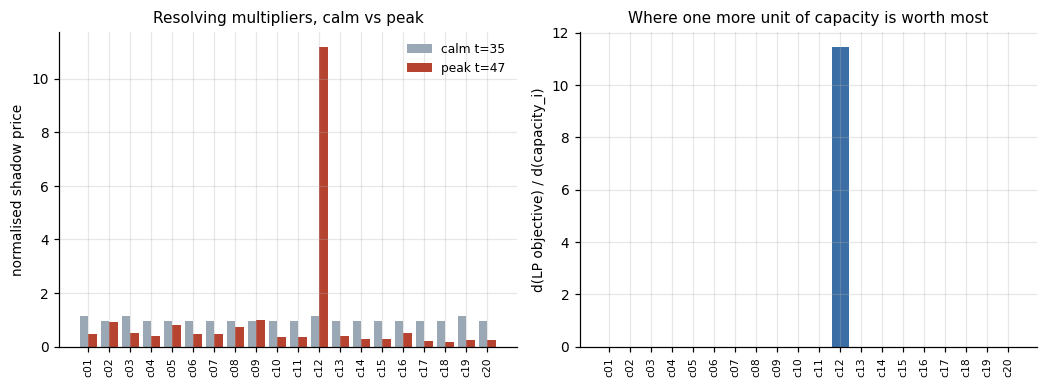


most valuable goods at the peak:
     peak price (t=47)  ratio peak/calm
c12             11.186            9.695
c09              0.988            1.027
c02              0.901            0.938

calm-period dispersion of prices: std(log p) = 0.0729
peak-period dispersion of prices: std(log p) = 0.8565
Price dispersion is the planner's own measure of how unevenly scarce the economy is.


In [4]:
shadow = pd.DataFrame({
    "calm price (t=35)": calm["prices"],
    "peak price (t=47)": peak["prices"],
    "ratio peak/calm": peak["prices"] / calm["prices"],
    "capacity value (peak)": peak["cap_duals"],
    "x at capacity (peak)": (np.isclose(peak["x"], peak["cap"], rtol=1e-9)).astype(int),
}, index=list(tech.sectors))
order = np.argsort(-shadow["peak price (t=47)"].to_numpy())
print("shadow prices, sorted by the peak-period value:")
print(shadow.iloc[order].round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
ax = axes[0]
xpos = np.arange(n)
ax.bar(xpos - 0.2, shadow["calm price (t=35)"], width=0.4, label="calm t=35", color="#9aa7b4")
ax.bar(xpos + 0.2, shadow["peak price (t=47)"], width=0.4, label="peak t=47", color="#b5432f")
ax.set_xticks(xpos)
ax.set_xticklabels(tech.sectors, rotation=90, fontsize=7)
ax.set_ylabel("normalised shadow price")
ax.set_title("Resolving multipliers, calm vs peak")
ax.legend(fontsize=8)

ax = axes[1]
ax.bar(xpos, shadow["capacity value (peak)"], color="#3b6ea5")
ax.set_xticks(xpos)
ax.set_xticklabels(tech.sectors, rotation=90, fontsize=7)
ax.set_ylabel("d(LP objective) / d(capacity_i)")
ax.set_title("Where one more unit of capacity is worth most")
fig.tight_layout()
plt.show()

top = shadow.sort_values("peak price (t=47)", ascending=False).head(3)
print("\nmost valuable goods at the peak:")
print(top[["peak price (t=47)", "ratio peak/calm"]].round(3).to_string())
print(f"\ncalm-period dispersion of prices: std(log p) = {np.std(np.log(calm['prices'])):.4f}")
print(f"peak-period dispersion of prices: std(log p) = {np.std(np.log(peak['prices'])):.4f}")
print("Price dispersion is the planner's own measure of how unevenly scarce the economy is.")

## 4 · 影子价格的两条警告

1. **对偶变量只在最优解处有定义，而最优解可能不唯一。** 我们加了 `mu = 1e-3` 的输出惩罚来挑一个解；换一个 `mu`，对偶变量会变，但**约束的紧/松结构**不会。所以"哪个影子价格高"是稳健的，"具体数值"依赖归一化和惩罚项。
2. **价格是相对的。** 机制把对偶变量除以其均值，所以只有比值有意义。拿它和真实价格水平比较是没有意义的——这也是为什么本 notebook 只比较**相对**差异。

这两条正是 LP 价格理论在计划经济讨论里的软肋：影子价格可以计算，但它是**计划的影子**，不是市场的价格。它告诉你"如果计划者能再多一单位商品，福利会提高多少"；它不告诉你"谁应该得到这一单位"。

*Two caveats: the duals are defined at an optimum that may not be unique (the tiny output penalty picks one), and prices are relative by construction. That is precisely the weakness of the LP-price argument in the calculation debate: a shadow price is the shadow of the plan, not a market price, and it says nothing about who should get the marginal unit.*

下面转向第二个主题：如果只让**一部分**商品走市场轨，会怎样？

## 5 · 双轨制：扫描 `theta`

`hybrid_dual_track` 的规则（见该模块的文档字符串）：

* 每个商品有 `theta` 的份额走**计划轨**：行政价、按优先级阶梯分配（中间投入 → 必需消费 → 其他消费 → 政府 → 投资）；
* 剩下的 `1 - theta` 走**市场轨**：价格随该轨道上观察到的超额需求调整，轨内所有人按比例分配、没有优先级；
* `theta = 1` 是纯计划，`theta = 0` 是纯市场。

`theta` 是本 notebook 的处理变量。对每个 `theta` 跑同一条冲击（同一个 cell id、同一个种子，所以外生流完全相同），记录福利、短缺、价格波动和计划轨的实际份额。

*Sweep theta from 0 to 1 on one identical shock. theta = 1 is pure plan, theta = 0 pure market; interior theta protects the plan track and lets the market track absorb the imbalance at a diverging price.*

注意一个细节：机制在 `Plan.meta` 里报告了**实际**的计划轨份额 `plan_track_share` 和市场价离散度 `market_price_dispersion`。它们不等于名义的 `theta`——因为供给收缩时计划轨的相对份额会变化。这个差别本身就是双轨制的一个特征，值得打印出来看。

In [5]:
THETAS = np.round(np.arange(0.0, 1.0001, 0.1), 2)
rows = []
diag_rows = []
for theta in THETAS:
    params = {"theta": float(theta)}
    scen = Scenario(
        id=CELL_ID + "_theta", mechanism="hybrid_dual_track", technology={},
        periods=60, burn_in=30, seeds=(SEED,), shocks=(SHOCK,),
        info=InfoRegime(lag=0), stock_ratio=0.10, demand=DemandProcess(),
        mechanism_params=params,
    )
    rec = ObsRecorder(get_mechanism("hybrid_dual_track", tech, params), 47)
    res = run_simulation(tech, rec, scen, seed=SEED)
    rm = res.run_metrics
    rows.append({
        "theta": float(theta),
        "mean_shortage": rm["mean_shortage_rate"],
        "peak_shortage": rm["max_shortage_rate"],
        "welfare": rm["mean_welfare"],
        "price_volatility": rm["mean_price_volatility"],
        "price_dispersion": rm["mean_price_dispersion"],
        "plan_fulfilment": rm["mean_plan_fulfilment"],
    })
    diag_rows.append({"theta": float(theta),
                      "plan_track_share (t=47)": rec.log["plan"].meta.get("plan_track_share"),
                      "market price dispersion (t=47)":
                          rec.log["plan"].meta.get("market_price_dispersion")})

frontier = pd.DataFrame(rows).set_index("theta")
diag = pd.DataFrame(diag_rows).set_index("theta")
print("theta sweep, one shock, one seed:")
print(frontier.round(4).to_string())
print("\ndual-track diagnostics reported by the mechanism itself, at the peak quarter:")
print(diag.round(4).to_string())
best = frontier["welfare"].idxmax()
print(f"\nbest welfare at theta = {best}  ({frontier['welfare'].max():.4f})")
print(f"welfare range: {frontier['welfare'].min():.4f} .. {frontier['welfare'].max():.4f}")
print(f"endpoints: theta=0 welfare {frontier.loc[0.0, 'welfare']:.4f}, "
      f"theta=1 welfare {frontier.loc[1.0, 'welfare']:.4f}")

theta sweep, one shock, one seed:
       mean_shortage  peak_shortage   welfare  price_volatility  price_dispersion  plan_fulfilment
theta                                                                                             
0.0           0.0423         0.1773  247.4409            0.0194            0.2996           0.9384
0.1           0.0423         0.1772  247.4257            0.0193            0.2866           0.9375
0.2           0.0423         0.1776  247.3593            0.0189            0.2683           0.9367
0.3           0.0424         0.1779  247.3355            0.0185            0.2493           0.9358
0.4           0.0425         0.1781  247.2959            0.0182            0.2299           0.9350
0.5           0.0423         0.1784  247.2074            0.0180            0.2104           0.9344
0.6           0.0416         0.1785  247.2111            0.0183            0.1918           0.9341
0.7           0.0414         0.1787  247.2044            0.0184            

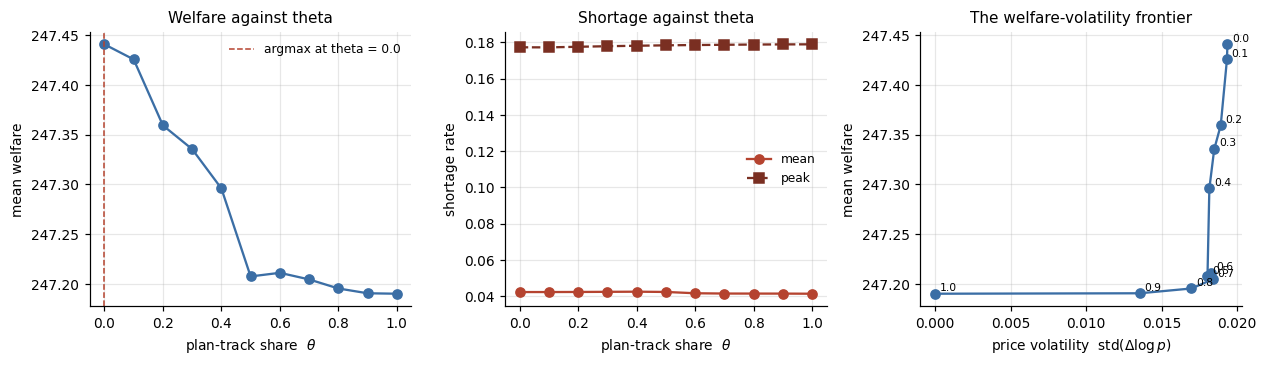

Reading the frontier: moving right costs stability, moving up gains welfare.
An interior optimum means you can have more of both by giving up some of either.
in this cell: argmax_theta W(theta) = 0.0 (at the boundary).
=> on this single cell the welfare curve is monotone in theta, which is exactly
   the pattern that would FALSIFY H5 if it survived 20 seeds. Do not conclude
   that the dual track is useless: check the pre-registered table in section 6.


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11.6, 3.4))

ax = axes[0]
ax.plot(frontier.index, frontier["welfare"], "o-", color="#3b6ea5")
ax.axvline(best, color="#b5432f", ls="--", lw=1, label=f"argmax at theta = {best}")
ax.set_xlabel("plan-track share  $\\theta$")
ax.set_ylabel("mean welfare")
ax.set_title("Welfare against theta")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(frontier.index, frontier["mean_shortage"], "o-", color="#b5432f", label="mean")
ax.plot(frontier.index, frontier["peak_shortage"], "s--", color="#7a2f22", label="peak")
ax.set_xlabel("plan-track share  $\\theta$")
ax.set_ylabel("shortage rate")
ax.set_title("Shortage against theta")
ax.legend(fontsize=8)

ax = axes[2]
ax.plot(frontier["price_volatility"], frontier["welfare"], "o-", color="#3b6ea5")
for theta, row in frontier.iterrows():
    ax.annotate(f"{theta:.1f}", (row["price_volatility"], row["welfare"]),
                fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_xlabel("price volatility  std($\\Delta \\log p$)")
ax.set_ylabel("mean welfare")
ax.set_title("The welfare-volatility frontier")
fig.tight_layout()
plt.show()
print("Reading the frontier: moving right costs stability, moving up gains welfare.")
print("An interior optimum means you can have more of both by giving up some of either.")
print(f"in this cell: argmax_theta W(theta) = {best} "
      f"({'interior' if 0 < best < 1 else 'at the boundary'}).")
if not (0 < best < 1):
    print("=> on this single cell the welfare curve is monotone in theta, which is exactly")
    print("   the pattern that would FALSIFY H5 if it survived 20 seeds. Do not conclude")
    print("   that the dual track is useless: check the pre-registered table in section 6.")

## 6 · 这是演示，不是检验

必须重复一遍：**上面这条前沿来自一个种子、一个冲击部门、一组默认参数。** 协议里的 H5 是这样写的：

> **H5.** 双轨制在福利—价格波动前沿上有一个关于 `theta` 的内点最优：`argmax_theta W(theta)` 严格位于 `(0, 1)` 内部。**若福利在测试网格上单调，则被证伪。**

所以正确做法是：20 个种子 × B5 的 `theta` 网格（11 档）× 2 个滞后，取每个 (theta, k) 单元内 20 个种子的均值，然后看 `argmax` 是否严格内点，并用配对差检验（同一种子内 `W(theta) - W(0)`）。本 notebook 演示了**流程**；检验在 `results/`（实验层）里。

*The frontier here comes from one seed. The pre-registered H5 test uses 20 seeds and a paired test on within-seed differences; this notebook demonstrates the procedure, and the test lives in ``results/``.*

我们可以顺手做一件有用的事：把上面这条前沿与 `results/` 里的 B5 表对比（如果实验层已经跑完）。这不是必须的，但能让你看到"演示"和"检验"的差距有多大。

In [7]:
from planlab.paths import results_dir

b5_table = results_dir() / "tables" / "t09_dual_track.csv"
if b5_table.exists():
    published = pd.read_csv(b5_table)
    print(f"found the pre-registered table {b5_table.relative_to(results_dir().parent)}:")
    print(published.head(12).to_string(index=False))
    print("\nThat table is the H5 evidence: 20 seeds per cell, both lags, and the")
    print("paired within-seed differences. This notebook's single-seed frontier is not.")
    have_published = True
else:
    print(f"results table not found at {b5_table}")
    print("The experiment layer has not produced block B5 yet. This notebook's own sweep")
    print("above is still valid as a demonstration of the procedure; re-run it after")
    print("`bash scripts/reproduce.sh` to see the seeded version.")
    have_published = False
print(f"\n(single-seed demonstration above; pre-registered table available: {have_published})")

found the pre-registered table results/tables/t09_dual_track.csv:
 lag_reporting  lag_effective  theta  n_seeds  mean_welfare  mean_welfare_sd  mean_welfare_loss  mean_shortage_rate  mean_shortage_essentials  mean_price_volatility  mean_plan_fulfilment  mean_x_over_base  mean_shortage_sd
             0              1    0.0       20       252.214         0.069557           0.033184            0.029670                  0.023657               0.009538              0.965901          0.967220          0.044950
             0              1    0.1       20       252.220         0.067035           0.033184            0.029951                  0.023663               0.009993              0.965325          0.967968          0.045635
             0              1    0.2       20       252.257         0.072498           0.033087            0.030257                  0.023844               0.009957              0.964576          0.968779          0.046369
             0              1    0.3      

## 7 · 小结与练习

**影子价格部分。** 我们写出了一个 40 变量、20 约束的 LP，解出来，把对偶变量取出来，并证明它们与 `lp_central` 报出的价格逐项相同（相对误差 < 1e-8）。结论：

* 对偶变量 = 物资平衡约束的边际福利价值 = Kantorovich 的结算乘数；
* 平静期它们接近福利权重，峰值期少数商品跳起来；
* 容量约束的对偶变量内生地告诉你"往哪里投资最值"。

**双轨部分。** `theta` 从 0 扫到 1，得到一条福利—波动前沿；机制自报的 `plan_track_share` 与名义 `theta` 不同，因为供给收缩时计划轨的相对份额会变。

*We solve the central LP by hand, extract its duals, and verify them against the mechanism's reported prices to 1e-8. Then we sweep the dual-track share and trace the welfare-volatility frontier, noting that the realised plan-track share differs from the nominal theta.*

### 练习

1. **惩罚项会改变对偶变量吗？** 把 `LP_PARAMS["output_penalty"]` 从 1e-3 改成 1e-1，重跑第 2 节。相对价格变了多少？"哪个约束紧"变了吗？（提示：看 `x at capacity` 的计数。）
2. **归一化。** 机制把对偶变量除以均值。把我们的价格乘以 2 再和机制比较，还会通过断言吗？如果不通过，说明断言检验的是**绝对**还是**相对**价格？（自己改断言代码想清楚。）
3. **投资信号。** 第 3 节右图里，容量的对偶变量最大的是哪个部门？把它和 `figure/` 里的冲击传播图对比：被冲击的 `c12` 是不是"最值得扩产"的那个？为什么不是？
4. **双轨的端点。** `theta = 1`（纯计划）与 `material_balance` 的结果一致吗？`theta = 0` 与 `market` 一致吗？如果不一致，差在哪里（提示：三个机制的 `form_plan` 完全不同，`theta` 只改变**分配**，不改变**计划**）。
5. **内点最优存在吗？** 用 3 个种子重跑第 5 节，把每个 `theta` 的福利均值画出来（带误差棒）。内点最优还在吗？如果 `theta = 0` 和 `theta = 1` 的差小于种子间的标准差，你还能说存在内点最优吗？
6. **进阶。** 影子价格理论说"对偶变量 = 放松约束的边际价值"。请构造一个实验验证它：把 `c12` 的产能人为提高 1%，重跑峰值期，看福利提高多少；再和峰值期 `c12` 的容量对偶变量比较。数量级对得上吗？（提示：对偶变量是**局部**的，1% 的扰动可能已经越过了线性区间。）

In [8]:
checks = [
    ("our LP reproduces the mechanism's plan (calm)",
     bool(np.allclose(calm["x"], log_calm["plan"].targets, rtol=1e-9, atol=1e-6)), "x matches"),
    ("our LP reproduces the mechanism's plan (peak)",
     bool(np.allclose(peak["x"], log_peak["plan"].targets, rtol=1e-9, atol=1e-6)), "x matches"),
    ("duals equal the reported prices (calm)",
     bool(np.allclose(calm["prices"], res_lp.records[34].price, rtol=1e-8, atol=1e-10)),
     "rel < 1e-8"),
    ("duals equal the reported prices (peak)",
     bool(np.allclose(peak["prices"], res_peak.records[46].price, rtol=1e-8, atol=1e-10)),
     "rel < 1e-8"),
    ("prices are normalised to mean one",
     bool(abs(np.mean(calm["prices"]) - 1) < 1e-12 and abs(np.mean(peak["prices"]) - 1) < 1e-12),
     "mean = 1"),
    ("peak scarcity raises price dispersion",
     bool(np.std(np.log(peak["prices"])) > np.std(np.log(calm["prices"]))),
     f"{np.std(np.log(calm['prices'])):.3f} -> {np.std(np.log(peak['prices'])):.3f}"),
    ("theta sweep covers the full [0, 1] grid",
     bool(np.isclose(frontier.index.min(), 0.0) and np.isclose(frontier.index.max(), 1.0)),
     f"{len(frontier)} points"),
    ("welfare is finite across the sweep", bool(np.all(np.isfinite(frontier["welfare"]))), "all finite"),
    ("the mechanism reports its own plan-track share",
     bool(diag["plan_track_share (t=47)"].notna().all()), "Plan.meta"),
]
print(f"{'check':52s} {'ok':>5s}  detail")
for name, ok, detail in checks:
    print(f"{name:52s} {str(ok):>5s}  {detail}")
assert all(c[1] for c in checks)
print(f"\nALL {len(checks)} CHECKS PASSED   (notebook runtime {time.perf_counter()-T0:.1f}s)")

check                                                   ok  detail
our LP reproduces the mechanism's plan (calm)         True  x matches
our LP reproduces the mechanism's plan (peak)         True  x matches
duals equal the reported prices (calm)                True  rel < 1e-8
duals equal the reported prices (peak)                True  rel < 1e-8
prices are normalised to mean one                     True  mean = 1
peak scarcity raises price dispersion                 True  0.073 -> 0.856
theta sweep covers the full [0, 1] grid               True  11 points
welfare is finite across the sweep                    True  all finite
the mechanism reports its own plan-track share        True  Plan.meta

ALL 9 CHECKS PASSED   (notebook runtime 1.2s)
